Perguntar Elson sobre a escala: Multipliquei x e y por 10, preciso alterar a escala do tempo e do campo?


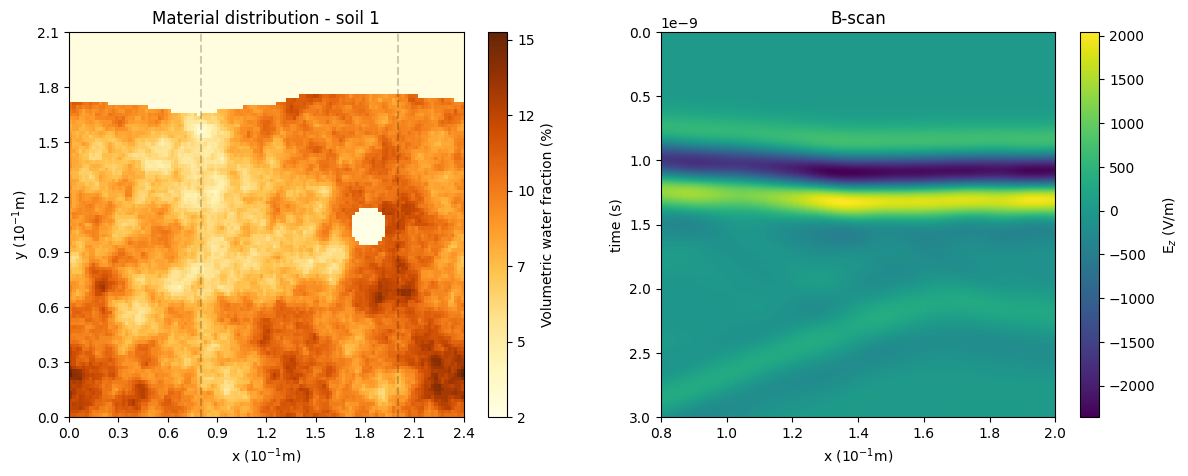

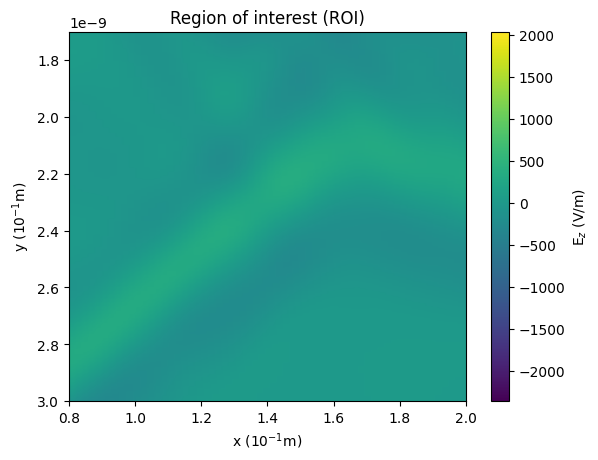

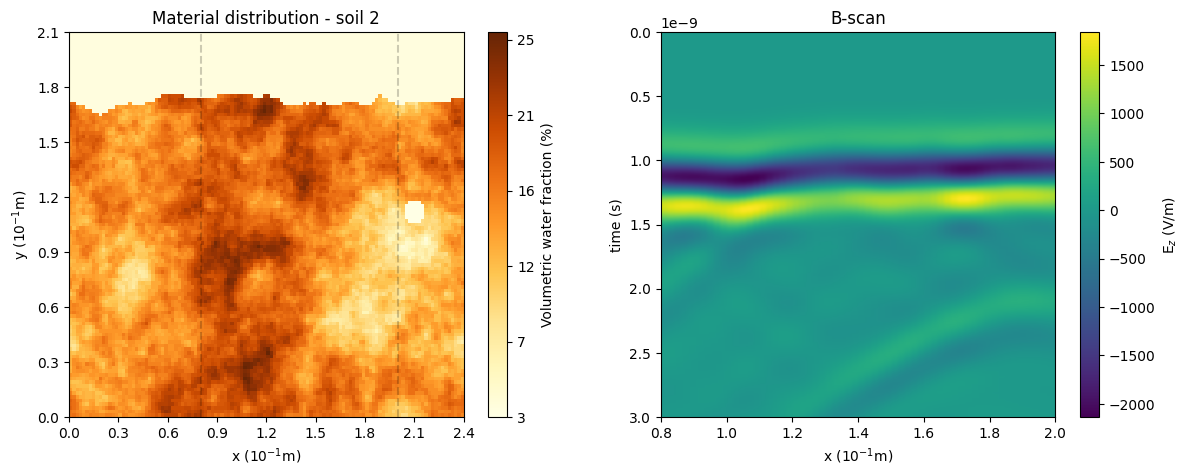

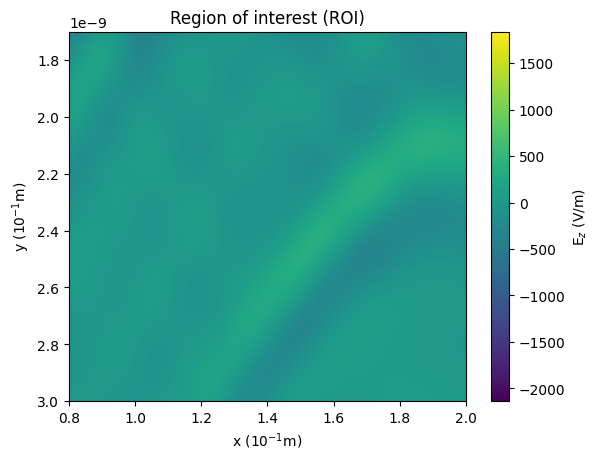

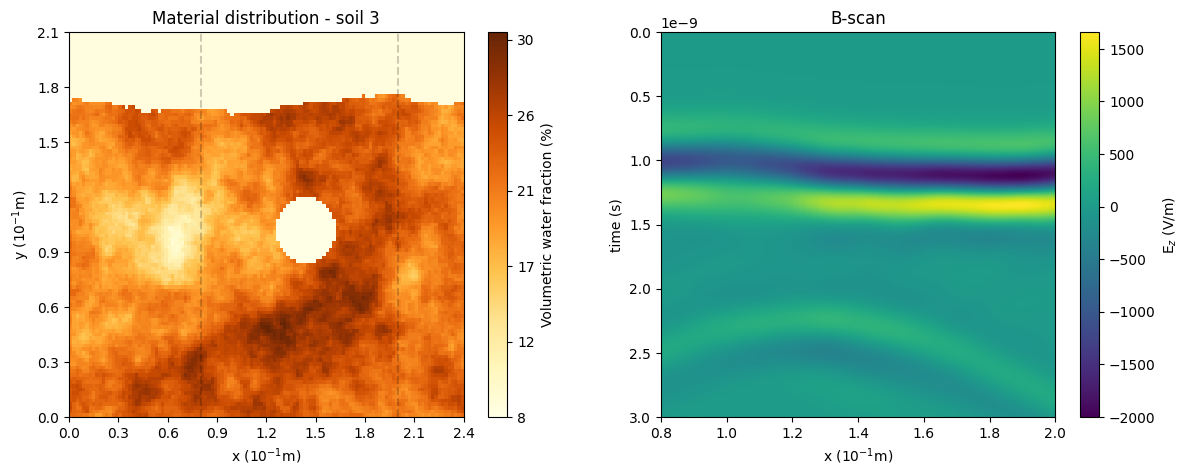

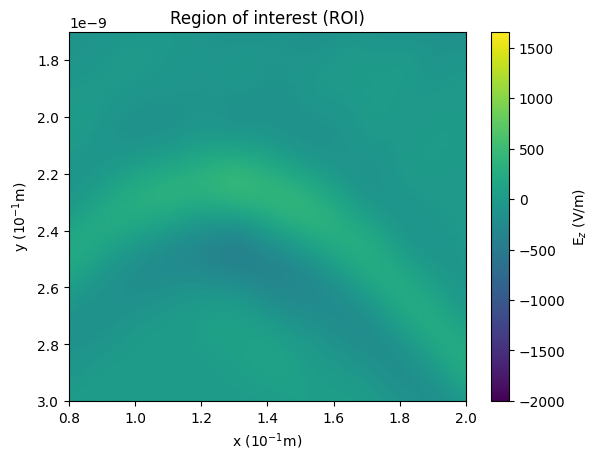

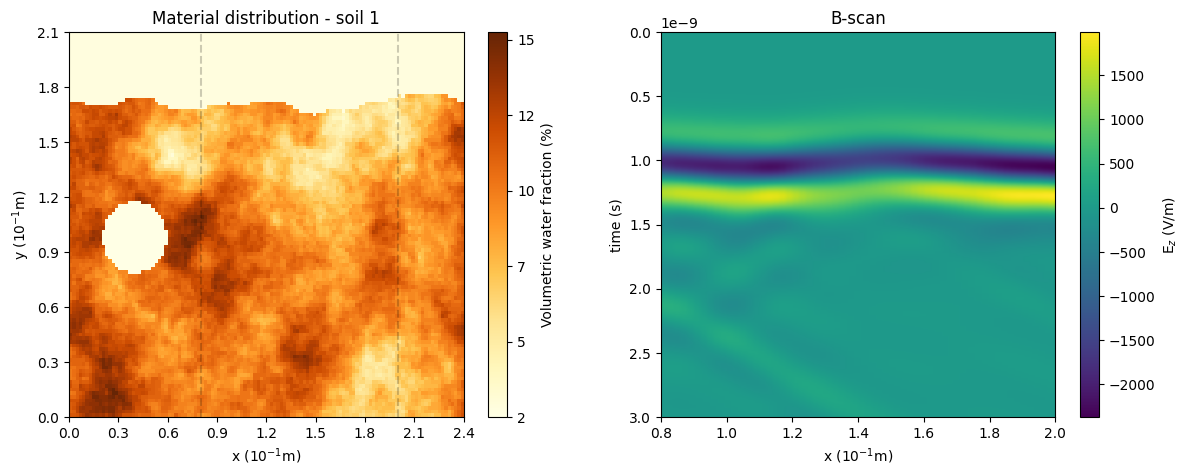

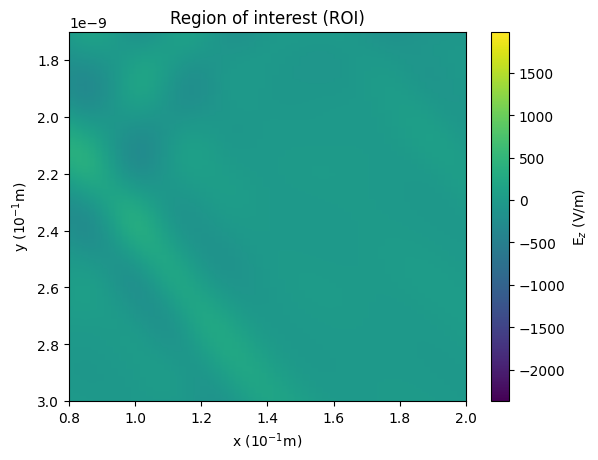

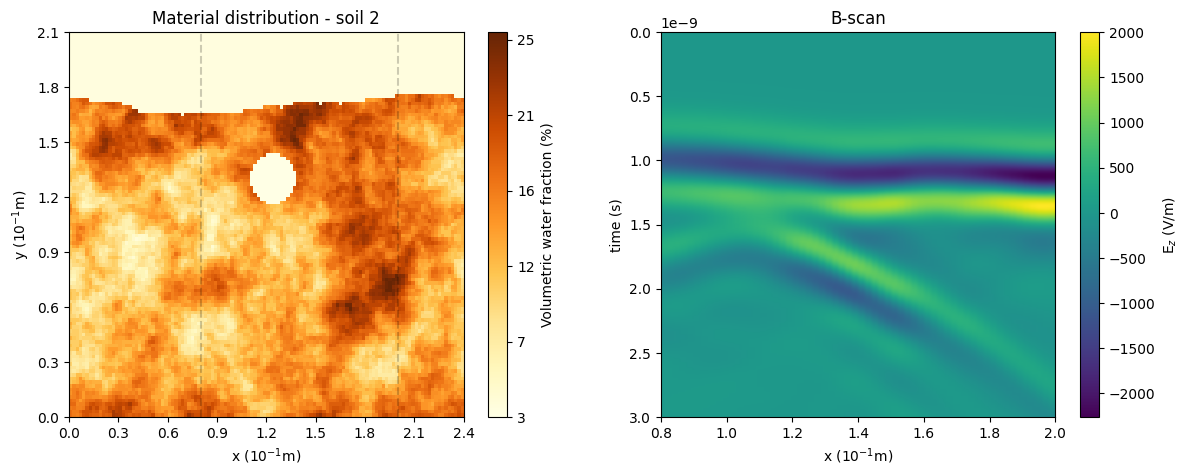

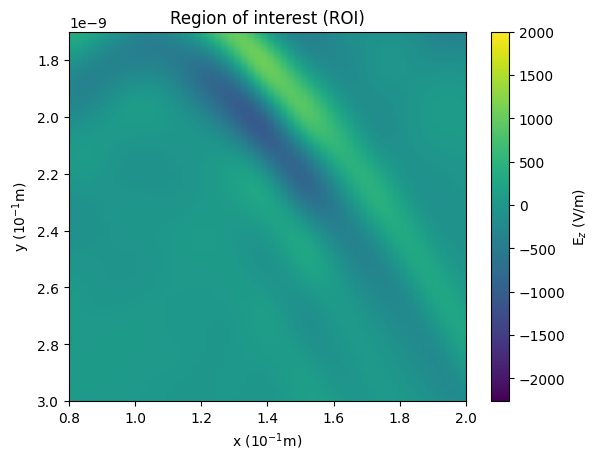

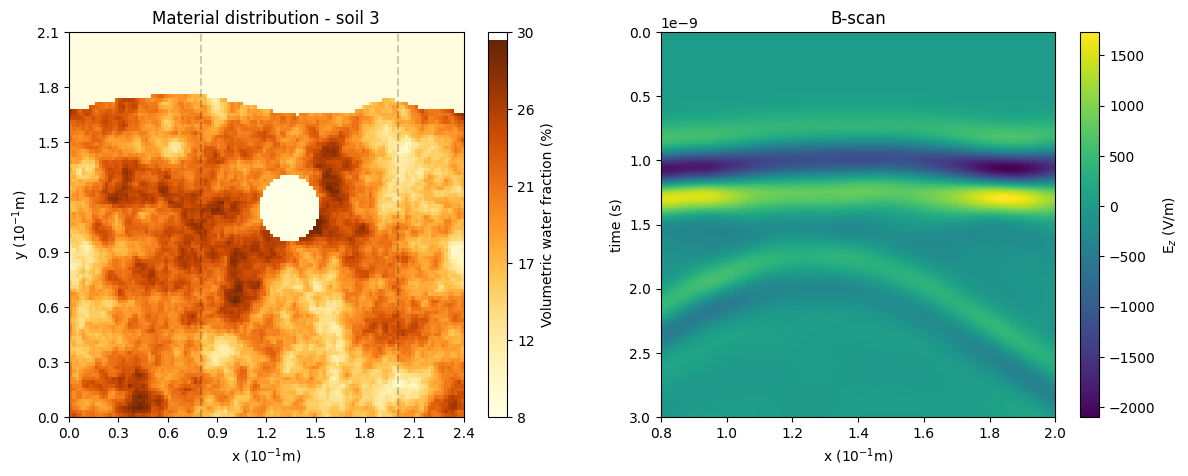

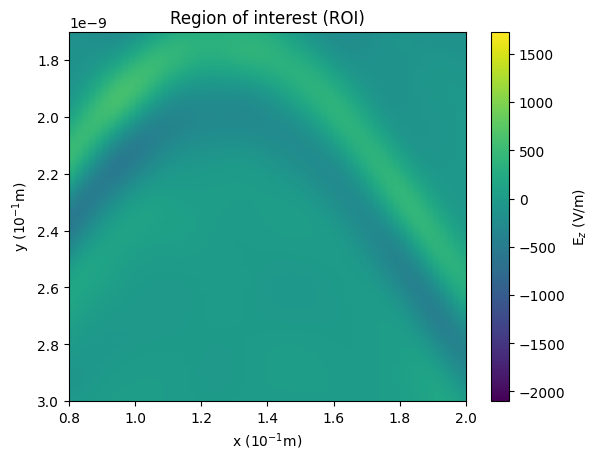

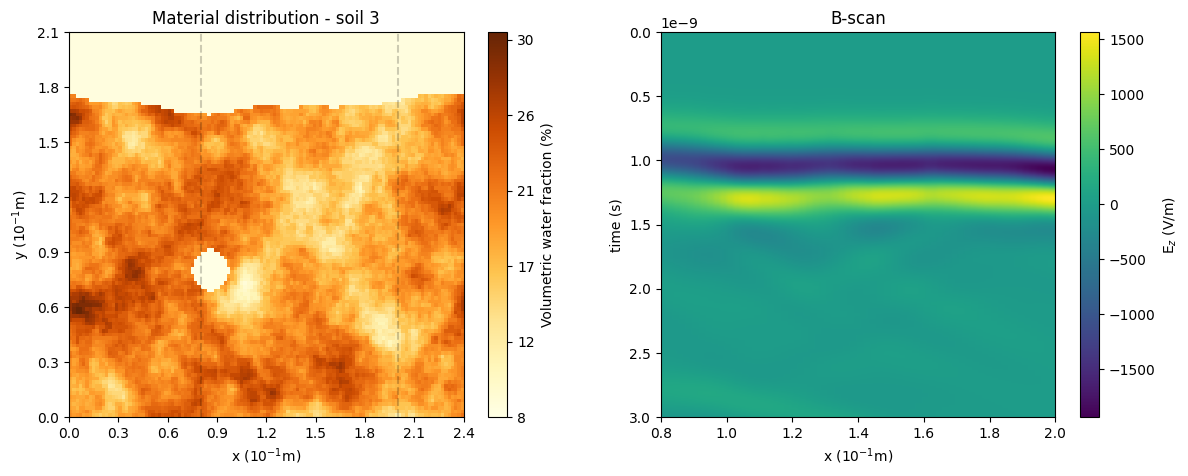

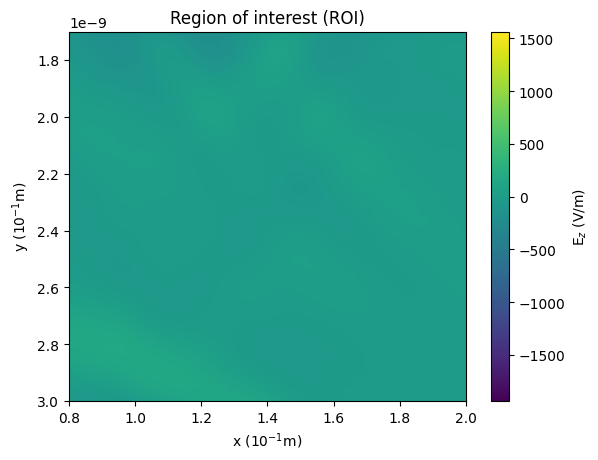

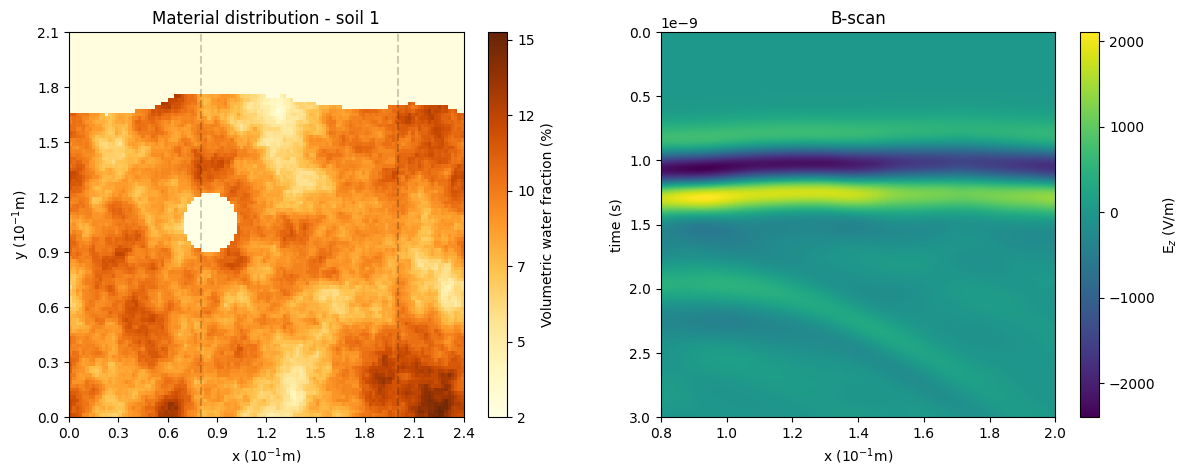

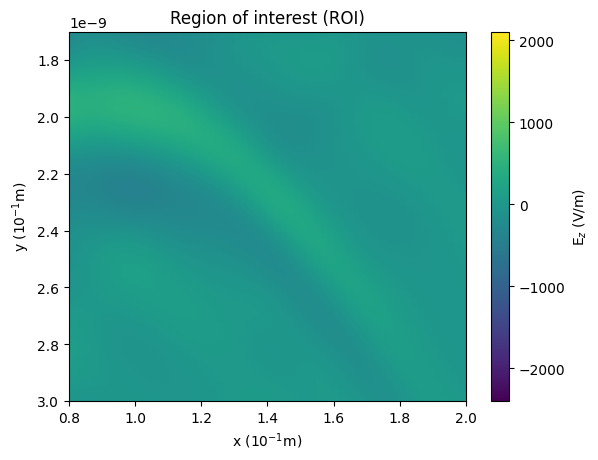

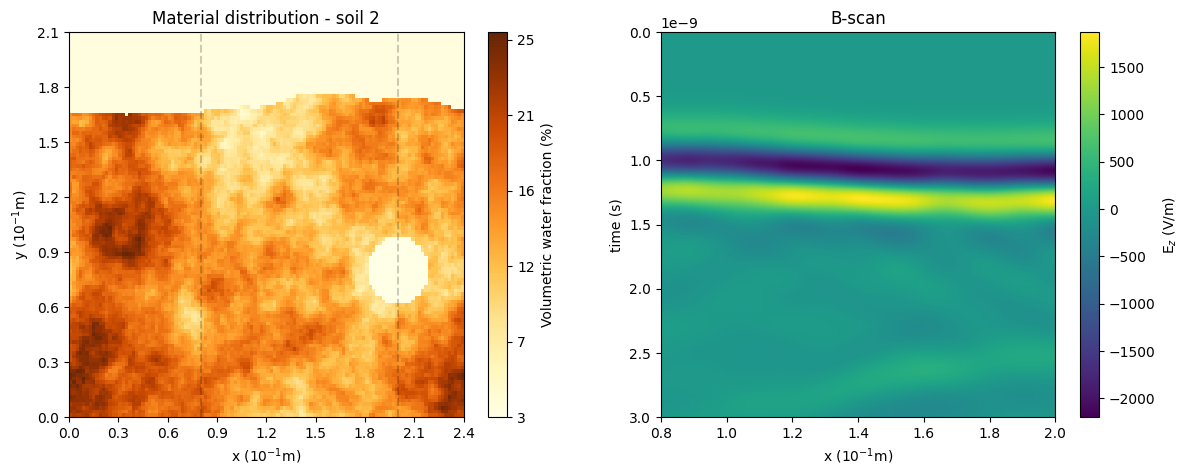

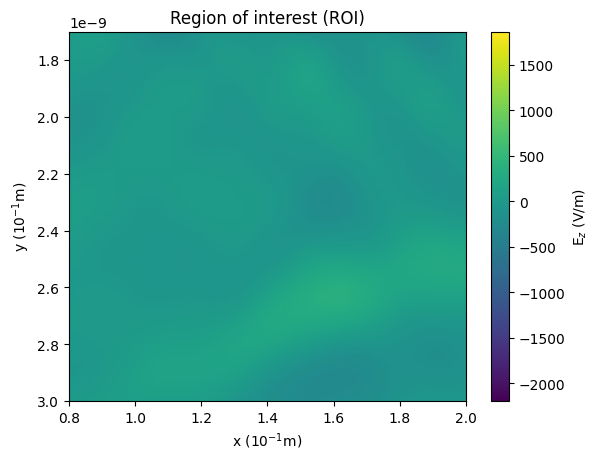

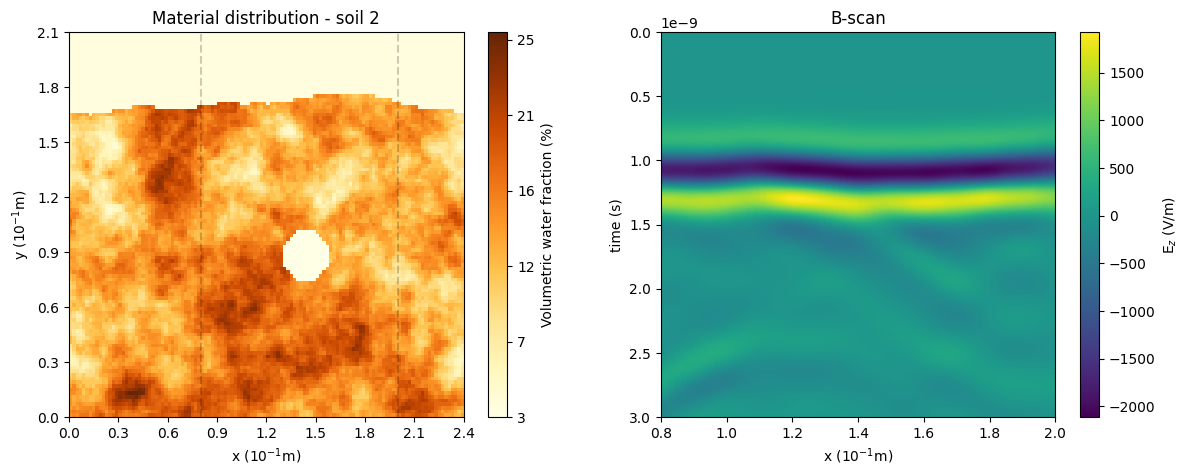

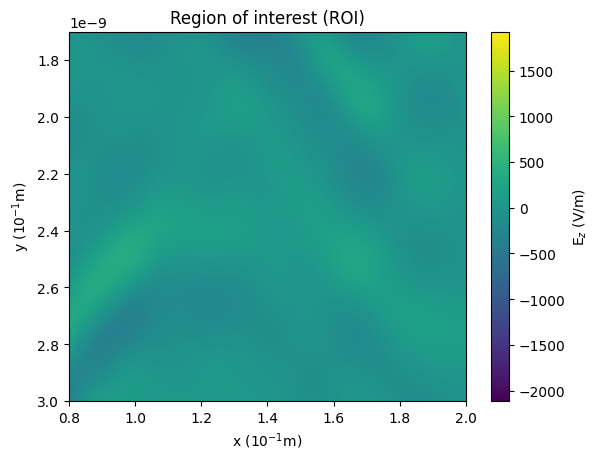

In [55]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import pyvista as pv
import pandas as pd

N = 10
Nf = 360

labels = pd.read_csv('labels1-10.csv')
solos = labels['soil_type']

print('Perguntar Elson sobre a escala: Multipliquei x e y por 10, preciso alterar a escala do tempo e do campo?')

for i in range(1,N+1):
    with h5py.File(f'Bscan{i}__merged.out', 'r') as f:
        rx = f['rxs/rx1']
        ez = rx['Ez'][:]

    if solos[i-1] == 1: ### SOLO ARENOSO
        u_min = 0.02
        u_max = 0.15
    elif solos[i-1] == 2: ### SOLO INTERMEDIÁRIO
        u_min = 0.03
        u_max = 0.25
    elif solos[i-1] == 3: ### SOLO ARGILOSO
        u_min = 0.08
        u_max = 0.30

    # Recorte da região de interesse - ROI
    ez_corr = ez[Nf + 1:637, 0:60]

    arquivo = rf"solo{i}.vti"
    dados = pv.read(arquivo)
    material = dados.cell_data["Material"]
    nx, ny, nz = dados.dimensions
    imagem = material.reshape(nz - 1, ny - 1, nx - 1)[0]

    print('====='*31)

    fig, ax = plt.subplots(1,2,figsize=(14,5))
    im1 = ax[1].imshow(ez,cmap='viridis',aspect='auto',extent=[0.8,2,3e-9,0])
    ax[1].set_title('B-scan')
    ax[1].set_ylabel('time (s)')
    ax[1].set_xlabel(r"x ($10^{-1}$m)")
    fig.colorbar(im1, ax=ax[1], label=r'E$_z$ (V/m)')

    im0 = ax[0].imshow(imagem, origin="lower", aspect="auto", cmap="YlOrBr",extent=[0,2.4,0,2.1])#,vmin=u_min,vmax=u_max)
    cbar0 = fig.colorbar(im0, ax=ax[0])
    ticks = np.linspace(0,50,6)
    water_fraction = np.linspace(u_min*100,u_max*100,6)
    cbar0.set_ticks(ticks)
    cbar0.set_ticklabels([f'{u:.0f}' for u in water_fraction])
    cbar0.set_label("Volumetric water fraction (%)")

    ax[0].set_xlabel(r"x ($10^{-1}$m)")
    ax[0].set_ylabel(r"y ($10^{-1}$m)")
    ax[0].set_xticks(np.arange(0,2.41,0.3))
    ax[0].set_yticks(np.arange(0,2.11,0.3))
    ax[0].axvline(x=0.8,color='black',ls='--',alpha=0.2)
    ax[0].axvline(x=2,color='black',ls='--',alpha=0.2)
    ax[0].set_title(f"Material distribution - soil {solos[i-1]}")

    plt.show()

    plt.figure()
    plt.title('Region of interest (ROI)')
    plt.xlabel(r"x ($10^{-1}$m)")
    plt.ylabel(r"y ($10^{-1}$m)")
    plt.imshow(ez_corr,cmap='viridis',aspect='auto',vmin=ez.min(),vmax=ez.max(),extent=[0.8,2,3e-9,1.7e-9])
    plt.colorbar(label=r'E$_z$ (V/m)')
    plt.show()
    print('====='*31)